# Netflix Movies & TV Shows — Exploratory Data Analysis
**Prepared by:** Anchal Chauhan  
**Project:** Data Analysis with Python  
**Submission date:** 30 November 2026

This notebook explores the Netflix titles dataset, using reproducible data cleaning, descriptive statistics and charts. The figures describe the supplied catalogue snapshot, not Netflix viewing figures or current availability.

## 1. Import libraries and load the dataset
Keep `netflix_titles.csv` in the same folder as this notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

file_path = Path('netflix_titles.csv')
netflix = pd.read_csv(file_path)
print('Rows and columns:', netflix.shape)
netflix.head()

Rows and columns: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 2. Understand the data
Before analysing the catalogue, I checked column types, missing values and duplicate identifiers.

In [2]:
display(netflix.info())
print('Missing values:')
print(netflix.isna().sum().sort_values(ascending=False))
print('Duplicate show IDs:', netflix.duplicated('show_id').sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


None

Missing values:
director        2634
country          831
cast             825
date_added        10
rating             4
duration           3
show_id            0
type               0
title              0
release_year       0
listed_in          0
description        0
dtype: int64
Duplicate show IDs: 0


## 3. Clean and prepare the dataset
Missing director, cast and country information is kept as missing rather than invented. For country comparisons, I use the first listed country and explain that this is a simplification of co-productions. For genres, I use the first listed category so each title is counted once.

In [3]:
df = netflix.drop_duplicates(subset='show_id').copy()
df['date_added'] = pd.to_datetime(df['date_added'].astype('string').str.strip(), errors='coerce')
df['year_added'] = df['date_added'].dt.year
df['primary_genre'] = df['listed_in'].str.split(',').str[0].str.strip()
df['primary_country'] = df['country'].fillna('Unknown').str.split(',').str[0].str.strip()
df['movie_minutes'] = pd.to_numeric(df['duration'].where(df['type'].eq('Movie')).str.extract(r'(\d+)')[0], errors='coerce')
df['seasons'] = pd.to_numeric(df['duration'].where(df['type'].eq('TV Show')).str.extract(r'(\d+)')[0], errors='coerce')
df['rating'] = df['rating'].fillna('Not specified')
print('Cleaned dataset:', df.shape)
print('Missing dates:', df['date_added'].isna().sum())

Cleaned dataset: (8807, 17)
Missing dates: 10


## 4. Movies versus TV shows
I first compared the two content types to understand the composition of the catalogue.

         Titles  Percentage
type                       
Movie      6131        69.6
TV Show    2676        30.4


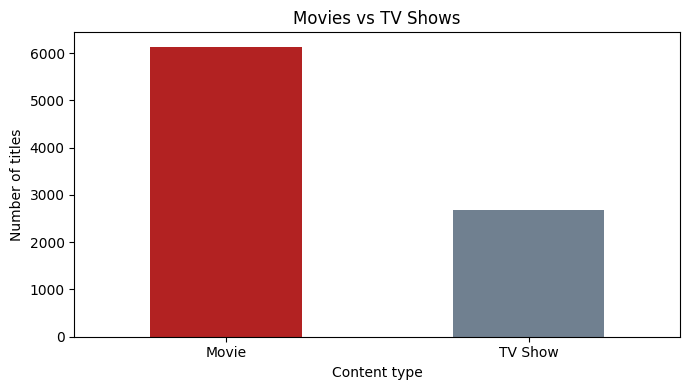

In [4]:
content = df['type'].value_counts()
print(pd.DataFrame({'Titles':content,'Percentage':(content/len(df)*100).round(1)}))
ax = content.plot(kind='bar', color=['firebrick','slategray'], figsize=(7,4))
ax.set(title='Movies vs TV Shows', ylabel='Number of titles', xlabel='Content type')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 5. Most common genres
`listed_in` can contain multiple labels. I use the first listed label for a straightforward, non-overlapping comparison.

primary_genre
Dramas                      1600
Comedies                    1210
Action & Adventure           859
Documentaries                829
International TV Shows       774
Children & Family Movies     605
Crime TV Shows               399
Kids' TV                     388
Stand-Up Comedy              334
Horror Movies                275
Name: count, dtype: int64


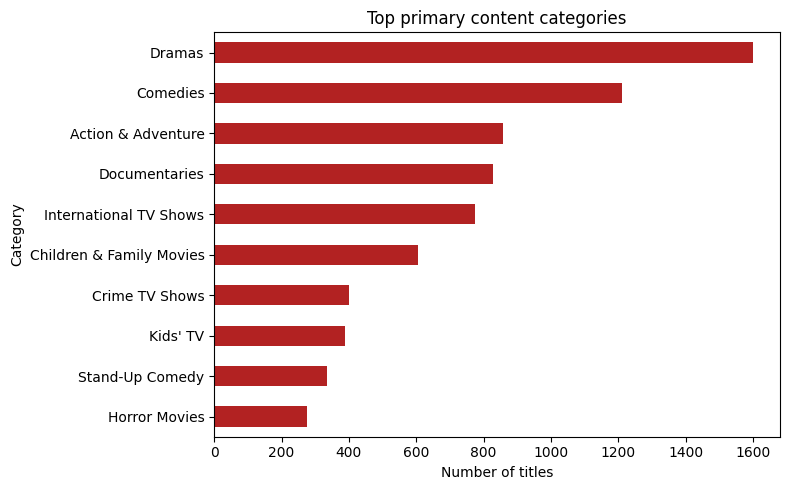

In [5]:
genres = df['primary_genre'].value_counts().head(10)
print(genres)
ax = genres.sort_values().plot(kind='barh', figsize=(8,5), color='firebrick')
ax.set(title='Top primary content categories', xlabel='Number of titles', ylabel='Category')
plt.tight_layout(); plt.show()

## 6. Countries represented
Country values sometimes contain multiple countries. The chart uses the first listed country, which should not be interpreted as the only producing country.

primary_country
United States     3211
India             1008
United Kingdom     628
Canada             271
Japan              259
France             212
South Korea        211
Spain              181
Mexico             134
Australia          117
Name: count, dtype: int64


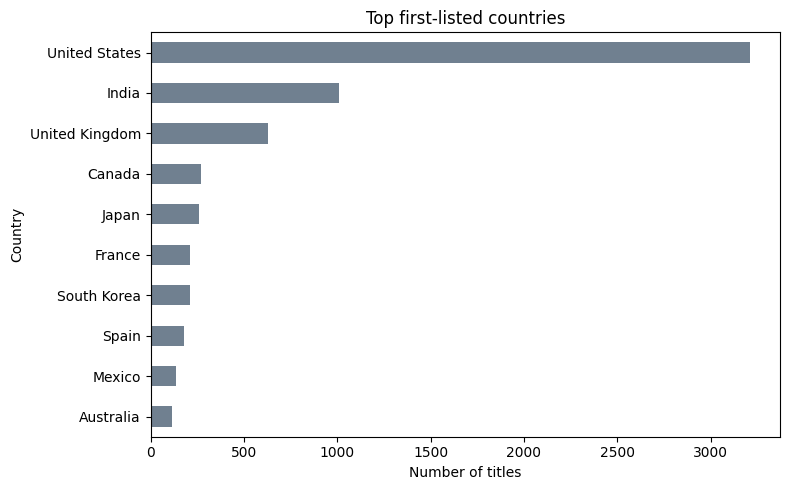

In [6]:
countries = df.loc[df['primary_country'] != 'Unknown','primary_country'].value_counts().head(10)
print(countries)
ax = countries.sort_values().plot(kind='barh', figsize=(8,5), color='slategray')
ax.set(title='Top first-listed countries', xlabel='Number of titles', ylabel='Country')
plt.tight_layout(); plt.show()

## 7. Content added over time
The `date_added` field tells us when a title was added to the catalogue, not when it was released or watched.

year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      24
2015.0      82
2016.0     429
2017.0    1188
2018.0    1649
2019.0    2016
2020.0    1879
2021.0    1498
Name: count, dtype: int64


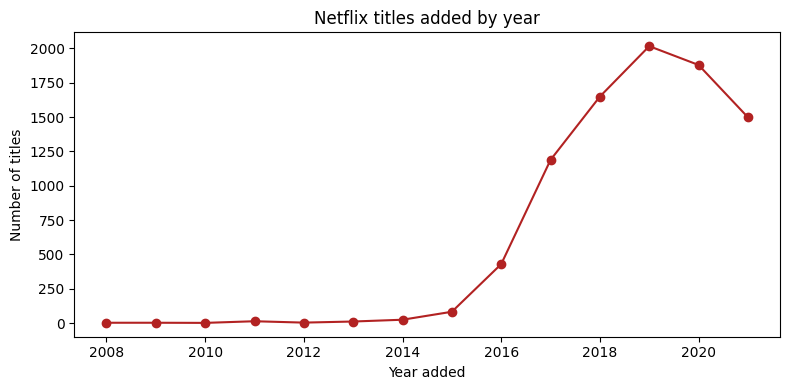

In [7]:
added = df['year_added'].value_counts().sort_index()
print(added)
ax = added.plot(marker='o', figsize=(8,4), color='firebrick')
ax.set(title='Netflix titles added by year', xlabel='Year added', ylabel='Number of titles')
plt.tight_layout(); plt.show()

## 8. Movie lengths and TV show seasons
Movie durations are measured in minutes, whereas TV show durations represent numbers of seasons. These are analysed separately.

Median movie length (minutes): 98.0
Median TV show seasons: 1.0


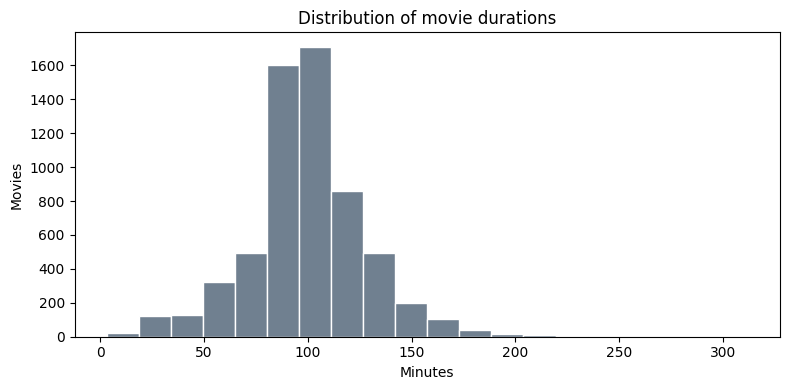

TV show season counts:
seasons
1.0     1793
2.0      425
3.0      199
4.0       95
5.0       65
6.0       33
7.0       23
8.0       17
9.0        9
10.0       7
11.0       2
12.0       2
Name: count, dtype: int64


In [8]:
movies = df.loc[df['type']=='Movie','movie_minutes'].dropna()
shows = df.loc[df['type']=='TV Show','seasons'].dropna()
print('Median movie length (minutes):', movies.median())
print('Median TV show seasons:', shows.median())
ax = movies.plot(kind='hist', bins=20, figsize=(8,4), color='slategray', edgecolor='white')
ax.set(title='Distribution of movie durations', xlabel='Minutes', ylabel='Movies')
plt.tight_layout(); plt.show()
print('TV show season counts:')
print(shows.value_counts().sort_index().head(12))

## 9. Key findings and limitations
The dataset is a historical snapshot of listed titles, so the results do not establish what is currently available, what people watched, or how much revenue Netflix earned. Missing metadata and multi-label categories can affect comparisons.

**My main takeaways:** Movies form the majority of titles in the supplied snapshot; content categories and producing countries are unevenly represented; and addition dates show how the recorded catalogue changed over time. These patterns can inform catalogue exploration, but they are not direct measures of viewer demand.

**Dataset:** [Netflix Movies and TV Shows (Kaggle)](https://www.kaggle.com/datasets/shivamb/netflix-shows).